# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:

# TODO 1: Number of voxels and storage size
NX, NY, NZ = 512, 512, 300

n_voxels = NX * NY * NZ
scan_mb = (n_voxels * 16) / (8 * 1024**2)

# TODO 2: Physical extent and voxel volume
extent_mm = (NX * 0.5, NY * 0.5, NZ * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: Rendering samples
samples_per_frame = NX * NZ * NY
samples_video = samples_per_frame * 120

# TODO 4: Early ray termination
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")

print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_Ignoring anisotropic voxel spacing causes two problems:

1. **Anatomical distortion:** Coronal and sagittal views will show incorrect proportions because the z-axis spacing (1.0 mm) is different from the x and y spacing (0.5 mm). Structures may appear stretched or compressed.

2. **Incorrect measurements:** Distances, dimensions and anatomical measurements will be inaccurate if the software assumes all voxels have equal physical dimensions.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centre (z, y, x): (28, 40, 41)
Lesion voxels detected: 431


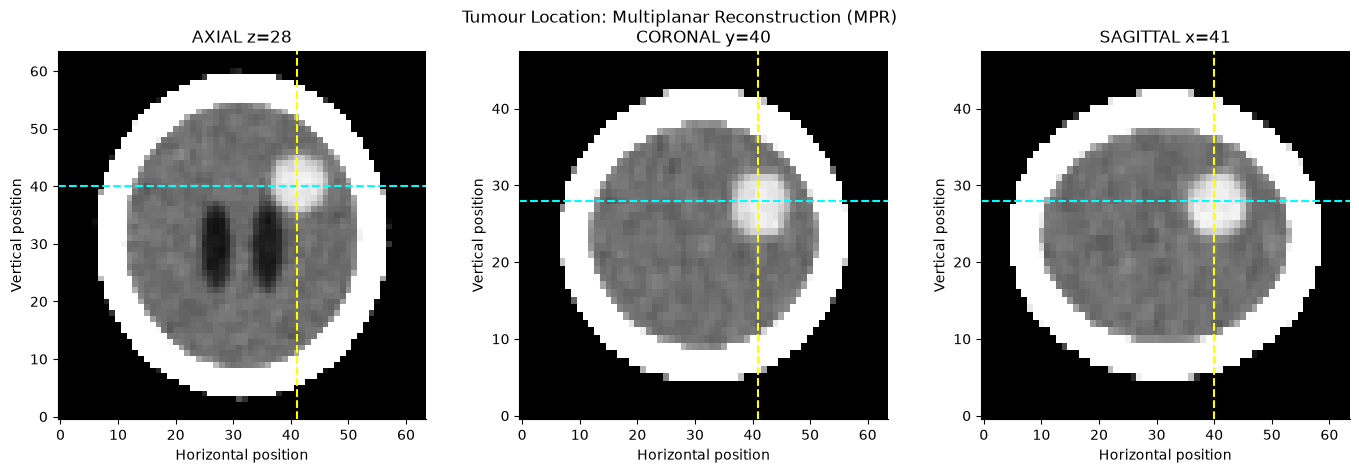

Distance from ground-truth centroid: 2.92 mm


In [3]:

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: Find candidate tumour voxels without using labels
bone = vol > 300

inside = ndimage.binary_fill_holes(bone) & ~bone

inside_eroded = ndimage.binary_erosion(
    inside,
    iterations=3
)

candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2: Largest connected component and centroid
comp, n_components = ndimage.label(candidates)

component_sizes = np.bincount(comp.ravel())
component_sizes[0] = 0

largest_component = component_sizes.argmax()

lesion = comp == largest_component

cz, cy, cx = np.round(
    np.argwhere(lesion).mean(axis=0)
).astype(int)

print(f"Lesion centre (z, y, x): ({cz}, {cy}, {cx})")
print(f"Lesion voxels detected: {lesion.sum()}")

# TODO 3: Axial, coronal and sagittal views
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view
axes[0].imshow(
    window(vol[cz], 80, 40),
    cmap="gray",
    origin="lower",
    aspect=1
)
axes[0].axhline(cy, color="cyan", linestyle="--")
axes[0].axvline(cx, color="yellow", linestyle="--")
axes[0].set_title(f"AXIAL z={cz}")

# Coronal view
axes[1].imshow(
    window(vol[:, cy, :], 80, 40),
    cmap="gray",
    origin="lower",
    aspect=ASPECT
)
axes[1].axhline(cz, color="cyan", linestyle="--")
axes[1].axvline(cx, color="yellow", linestyle="--")
axes[1].set_title(f"CORONAL y={cy}")

# Sagittal view
axes[2].imshow(
    window(vol[:, :, cx], 80, 40),
    cmap="gray",
    origin="lower",
    aspect=ASPECT
)
axes[2].axhline(cz, color="cyan", linestyle="--")
axes[2].axvline(cy, color="yellow", linestyle="--")
axes[2].set_title(f"SAGITTAL x={cx}")

for ax in axes:
    ax.set_xlabel("Horizontal position")
    ax.set_ylabel("Vertical position")

plt.suptitle("Tumour Location: Multiplanar Reconstruction (MPR)")
plt.tight_layout()
plt.show()

# TODO 4: Evaluation only (ground truth)
true_centroid = np.argwhere(labels == 5).mean(axis=0)

detected_centroid = np.array([cz, cy, cx])

distance_mm = np.linalg.norm(
    (detected_centroid - true_centroid) * np.array(SPACING)
)

print(f"Distance from ground-truth centroid: {distance_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_The erosion step removes the boundary voxels near the skull where the partial-volume effect occurs. Partial-volume voxels contain a mixture of different tissues, causing their intensity values to overlap with the tumour's intensity range. Without erosion, these boundary voxels could be incorrectly classified as tumour tissue. Erosion reduces this false detection and improves the segmentation accuracy.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


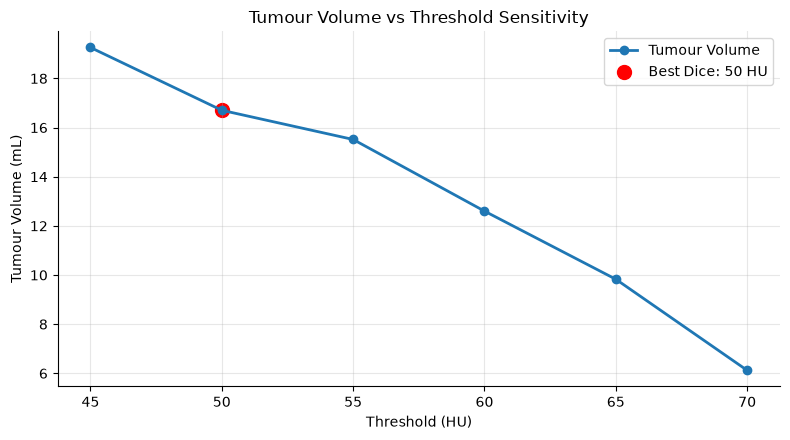

Reported volume range: 6.12 - 19.26 mL
Best threshold: 50 HU
Best Dice score: 0.994


In [4]:

truth = labels == 5
rows = []

# TODO 1 & 2: Threshold-based connected components and volume
for c in [45, 50, 55, 60, 65, 70]:

    comp, n = ndimage.label(vol > c)

    region = comp == comp[cz, cy, cx]

    voxel_count = region.sum()

    volume_ml = voxel_count * VOXEL_MM3 / 1000

    dice_score = (
        2 * (region & truth).sum()
        / (region.sum() + truth.sum())
    )

    rows.append({
        "threshold_hu": c,
        "voxels": int(voxel_count),
        "volume_ml": volume_ml,
        "dice_vs_truth": dice_score
    })

table = pd.DataFrame(rows).round(3)

display(table)

# TODO 3: Plot volume against threshold
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    table["threshold_hu"],
    table["volume_ml"],
    marker="o",
    linewidth=2,
    label="Tumour Volume"
)

best_index = table["dice_vs_truth"].idxmax()

best_threshold = table.loc[best_index, "threshold_hu"]

best_volume = table.loc[best_index, "volume_ml"]

ax.scatter(
    best_threshold,
    best_volume,
    color="red",
    s=100,
    label=f"Best Dice: {best_threshold} HU"
)

ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Tumour Volume (mL)")
ax.set_title("Tumour Volume vs Threshold Sensitivity")

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: Report volume range
min_volume = table["volume_ml"].min()
max_volume = table["volume_ml"].max()

print(f"Reported volume range: {min_volume:.2f} - {max_volume:.2f} mL")
print(f"Best threshold: {best_threshold} HU")
print(f"Best Dice score: {table.loc[best_index, 'dice_vs_truth']:.3f}")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_In real clinical practice, I would select the threshold based on anatomical boundaries, image intensity and expert radiologist validation. I would compare multiple threshold values and select the one that provides the most anatomically reasonable segmentation.

To communicate uncertainty, I would show the tumour boundaries at different thresholds using different coloured outlines and report the estimated volume as a range rather than presenting a single measurement as exact. This helps the surgeon understand how threshold selection affects tumour volume.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

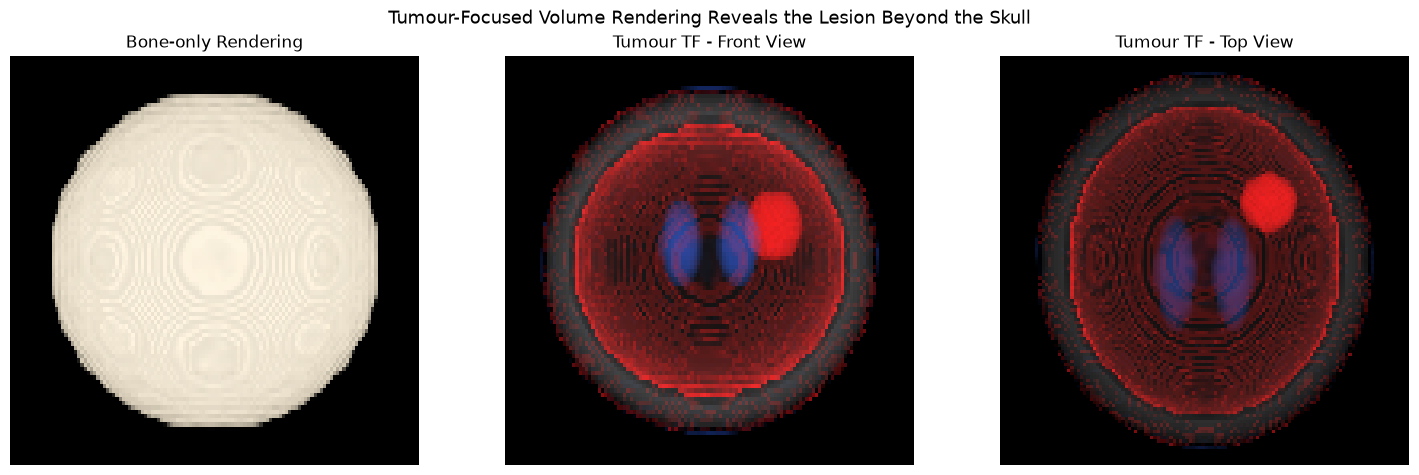

In [5]:

# Given bone transfer function
bone_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (200, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.3),
    (1500, (1, 1, 1), 0.6)
])

# TODO 2: Design tumour transfer function
tumour_tf = make_tf([
    # Air: fully transparent
    (-1000, (0, 0, 0), 0),
    (4, (0, 0, 0), 0),

    # CSF: blue and faint
    (5, (0.2, 0.4, 1), 0.025),
    (20, (0.2, 0.4, 1), 0.025),

    # Brain / soft tissue: transparent
    (28, (0, 0, 0), 0),
    (54, (0, 0, 0), 0),

    # Tumour: red
    (60, (1, 0.1, 0.1), 0.14),
    (80, (1, 0.1, 0.1), 0.14),

    # Other soft tissue: transparent
    (95, (0, 0, 0), 0),
    (299, (0, 0, 0), 0),

    # Bone: almost transparent
    (300, (1, 1, 1), 0.005),
    (1500, (1, 1, 1), 0.005)
])

# TODO 1 & 3: Render bone and tumour views
bone_C, bone_A = render(
    vol,
    bone_tf,
    axis=1
)

front_C, front_A = render(
    vol,
    tumour_tf,
    axis=1
)

top_C, top_A = render(
    vol,
    tumour_tf,
    axis=0
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# Bone render
axes[0].imshow(
    np.clip(bone_C, 0, 1),
    origin="lower",
    aspect=ASPECT
)
axes[0].set_title("Bone-only Rendering")

# Tumour front view
axes[1].imshow(
    np.clip(front_C, 0, 1),
    origin="lower",
    aspect=ASPECT
)
axes[1].set_title("Tumour TF - Front View")

# Tumour top view
axes[2].imshow(
    np.clip(top_C, 0, 1),
    origin="lower",
    aspect=1
)
axes[2].set_title("Tumour TF - Top View")

for ax in axes:
    ax.axis("off")

# TODO 4: Conclusion-style title
plt.suptitle(
    "Tumour-Focused Volume Rendering Reveals the Lesion Beyond the Skull",
    fontsize=13
)

plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_The faint red rim is caused by the partial-volume effect and overlapping intensity ranges between brain tissue and the tumour. Some boundary voxels have intensities similar to the tumour and are therefore displayed in red by the transfer function.

**Segmentation** is a technique from Slides 31–32 that can remove this unwanted region by identifying the tumour as a separate structure. A transfer function alone cannot reliably distinguish tissues with overlapping intensity values because it assigns colour and opacity based on intensity rather than anatomical identity.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_The detected lesion is located near the centre of the head volume, at approximately (z=28, y=40, x=41), with an estimated volume range of 6.12–19.26 mL depending on the selected HU threshold. The best Dice overlap in this evaluation was obtained at 50 HU, with a score of 0.994. I recommend opening the tumour-board meeting with the Multiplanar Reconstruction (MPR) view because axial, coronal and sagittal slices expose internal structures and provide complementary anatomical information without the occlusion associated with 3-D rendering. The segmentation and volume measurements can then support the discussion of tumour size and location. One important limitation of 3-D volume rendering is that overlapping tissue intensities and opacity accumulation can hide or incorrectly highlight structures, so the render should not be treated as the only source of anatomical information.